# inicio

In [1]:
#solo es para ver si esta tomando mi ambiente
import sys
print(sys.executable)

c:\proye_shada\Comercio\.venv\Scripts\python.exe


In [2]:
# Cargar todas las librerías
import pandas as pd
import os       #para ver si logro llegar al archivo con la ruta de datos
import matplotlib.pyplot as plt

In [3]:
print("Carpeta actual:", os.getcwd())
print("Contenido de la carpeta:", os.listdir())

#C:\proye_shada\Comercio\data\Online_Retail.xlsx
#df_retail = pd.read_excel('data/Online_Retail.xlsx')---------Esta ruta es para python
df_retail = pd.read_excel('../data/Online_Retail.xlsx')

Carpeta actual: c:\proye_shada\Comercio\notebooks
Contenido de la carpeta: ['comercio.py', 'comercio2.ipynb']


In [4]:
# Muestra los nombres de las columnas

print(df_retail.columns)

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')


In [5]:
#se procede a cambiar los nombres de las columnas por unas mas claras
#cambio de nombres de las columnas

nuevos_nombres = {
    'InvoiceNo': 'num_factura',
    'StockCode': 'cod_articulo',
    'Description': 'descripcion',
    'Quantity': 'cantidad',
    'InvoiceDate': 'fh_factura',
    'UnitPrice': 'precio_unitario',
    'CustomerID': 'id_cliente',
    'Country': 'pais'
}

df_retail = df_retail.rename(columns=nuevos_nombres)
print('*' * 120)

print(df_retail.columns.tolist())

************************************************************************************************************************
['num_factura', 'cod_articulo', 'descripcion', 'cantidad', 'fh_factura', 'precio_unitario', 'id_cliente', 'pais']


#### Extracción de solo 5 registros a manera de exploración

In [6]:
print('*' * 120)
print('*' * 40 +'df_retail------- solo los 5 registros' + '*' * 40)
print(df_retail.head())
print('*' * 120)

************************************************************************************************************************
****************************************df_retail------- solo los 5 registros****************************************
  num_factura cod_articulo                          descripcion  cantidad  \
0      536365       85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1      536365        71053                  WHITE METAL LANTERN         6   
2      536365       84406B       CREAM CUPID HEARTS COAT HANGER         8   
3      536365       84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4      536365       84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

           fh_factura  precio_unitario  id_cliente            pais  
0 2010-12-01 08:26:00             2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00             3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00             2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00 

#### información de las columnas

In [7]:
print('*' * 120)
print('*' * 40 +'df_retail' + '*' * 40)
#display(df_calls.head())
print('*' * 120)
print(df_retail.info())
print('*' * 120)

************************************************************************************************************************
****************************************df_retail****************************************
************************************************************************************************************************
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   num_factura      541909 non-null  object        
 1   cod_articulo     541909 non-null  object        
 2   descripcion      540455 non-null  object        
 3   cantidad         541909 non-null  int64         
 4   fh_factura       541909 non-null  datetime64[us]
 5   precio_unitario  541909 non-null  float64       
 6   id_cliente       406829 non-null  float64       
 7   pais             541909 non-null  str           
dtypes: datetime64[us](1), fl

#### Exploración de los valores ausentes

In [8]:
#antes de comenzar otra vez con cambios hagamos la copia y trabajemos en ella

df_retail_2 = df_retail.copy()

In [9]:
print('*' * 120)
print('*' * 40 +'df_retail_2------- revisión de valores ausentes' + '*' * 40)
print(df_retail_2.isna().sum())
print('*' * 120)


************************************************************************************************************************
****************************************df_retail_2------- revisión de valores ausentes****************************************
num_factura             0
cod_articulo            0
descripcion          1454
cantidad                0
fh_factura              0
precio_unitario         0
id_cliente         135080
pais                    0
dtype: int64
************************************************************************************************************************


📌 Se observan que hay valores ausentes en la descripción y en el id_cliente, antes de proceder a eliminarlos, <br>
vamos a revisar si hay valores duplicados, para realizar una limpieza mas generica creo que lo mas importante es quitar duplicados,<br>
por que eso no afectaria mucho que si elimino algunos datos con valores con inconsitencias


#### Tomemos un punto importante

En análisis de datos, limpiar no significa eliminar todo lo que parece extraño.

Por ejemplo:

* Una cantidad negativa podría ser una devolución, no necesariamente que se equivocaron, o que son datos erroneos

* Un precio cero podría corresponder a una operación especial.

* Un cliente ausente no significa necesariamente que la venta sea inválida.

* Una descripción ausente sí es un problema de calidad, pero su impacto depende del análisis que se quiera realizar.

#### Revisar si hay valores duplicados¶

In [10]:
#antes que nada vamos a cambiar el tipo flotante de id_cliente
df_retail_2['id_cliente'] = df_retail_2['id_cliente'].astype('Int64')

In [11]:
# Contar duplicados explícitos
print(df_retail_2.duplicated().sum())

5268


Visualizemos los registros duplicados completos, antes de decidir si los quitamos o los mantenemos,<br> se puede ver que tenemos 5268 registros duplicados

In [12]:
duplicados = df_retail_2[
    df_retail_2.duplicated(keep=False)
]

duplicados.head(10)

,num_factura,cod_articulo,descripcion,cantidad,fh_factura,precio_unitario,id_cliente,pais
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920,United Kingdom


In [13]:
print(
    "Facturas diferentes entre los duplicados:",
    duplicados['num_factura'].nunique()
)

Facturas diferentes entre los duplicados: 1933


In [14]:
duplicados.head(10)

,num_factura,cod_articulo,descripcion,cantidad,fh_factura,precio_unitario,id_cliente,pais
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920,United Kingdom


In [15]:
df_retail_2[
    df_retail_2.duplicated(keep=False)
].sort_values(
    by=['num_factura', 'cod_articulo']
).head(20)


,num_factura,cod_articulo,descripcion,cantidad,fh_factura,precio_unitario,id_cliente,pais
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920,United Kingdom


In [16]:
df_retail_2[
    (df_retail_2['num_factura'] == '536409') &
    (df_retail_2['cod_articulo'].isin(['22111', '22866', '22900']))
]

,num_factura,cod_articulo,descripcion,cantidad,fh_factura,precio_unitario,id_cliente,pais


In [17]:
df_retail_2[
    (df_retail_2['num_factura'] == '536409') &
    df_retail_2.duplicated(keep=False)
]

,num_factura,cod_articulo,descripcion,cantidad,fh_factura,precio_unitario,id_cliente,pais


In [18]:
print(df_retail_2['num_factura'].dtype)
print(df_retail_2['cod_articulo'].dtype)

object
object


In [19]:
df_retail_2[
    df_retail_2['num_factura'].astype(str).str.strip() == '536409'
]

,num_factura,cod_articulo,descripcion,cantidad,fh_factura,precio_unitario,id_cliente,pais
483,536409,90199C,5 STRAND GLASS NECKLACE CRYSTAL,3,2010-12-01 11:45:00,6.35,17908,United Kingdom
484,536409,21479,WHITE SKULL HOT WATER BOTTLE,1,2010-12-01 11:45:00,3.75,17908,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
486,536409,22785,SQUARECUSHION COVER PINK UNION FLAG,1,2010-12-01 11:45:00,6.75,17908,United Kingdom
487,536409,22975,SPACEBOY CHILDRENS EGG CUP,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
488,536409,22972,CHILDREN'S SPACEBOY MUG,1,2010-12-01 11:45:00,1.65,17908,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
490,536409,22568,FELTCRAFT CUSHION OWL,1,2010-12-01 11:45:00,3.75,17908,United Kingdom
491,536409,85116,BLACK CANDELABRA T-LIGHT HOLDER,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
492,536409,22664,TOY TIDY DOLLY GIRL DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom


In [20]:
factura_536409 = df_retail_2[
    df_retail_2['num_factura'].astype(str).str.strip() == '536409'
]

factura_536409[
    factura_536409.duplicated(keep=False)
].sort_values('cod_articulo')

,num_factura,cod_articulo,descripcion,cantidad,fh_factura,precio_unitario,id_cliente,pais
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom


In [21]:
# Contar los registros duplicados exactos
duplicados_exactos = df_retail_2.duplicated().sum()

print("Registros duplicados exactos:", duplicados_exactos)

Registros duplicados exactos: 5268


In [22]:
# antes de eliminar hagamos un respaldo hasta aqui

df_retail_3 = df_retail_2.copy()

In [23]:
df_retail_sin_duplicados = df_retail_3.drop_duplicates()

print("Filas originales:", len(df_retail_3))
print("Filas sin duplicados:", len(df_retail_sin_duplicados))
print("Filas eliminadas:", len(df_retail_3) - len(df_retail_sin_duplicados))

Filas originales: 541909
Filas sin duplicados: 536641
Filas eliminadas: 5268


In [24]:
print('*' * 120)
print('*' * 40 +'df_retail_sin_duplicados------- revisión de valores ausentes' + '*' * 40)
print(df_retail_sin_duplicados.isna().sum())
print('*' * 120)


************************************************************************************************************************
****************************************df_retail_sin_duplicados------- revisión de valores ausentes****************************************
num_factura             0
cod_articulo            0
descripcion          1454
cantidad                0
fh_factura              0
precio_unitario         0
id_cliente         135037
pais                    0
dtype: int64
************************************************************************************************************************


In [25]:
porcentaje_ausentes = (
    df_retail_sin_duplicados.isna().mean() * 100
).round(2)

print(porcentaje_ausentes.sort_values(ascending=False))

id_cliente         25.16
descripcion         0.27
cod_articulo        0.00
num_factura         0.00
cantidad            0.00
fh_factura          0.00
precio_unitario     0.00
pais                0.00
dtype: float64


Aqui se ve claramente como se comportan los valores ausentes:

* los ---->id_cliente tiene un 25.16 %----->Aproximadamente 1 de cada 4 registros no tiene identificado al cliente.
* ----->descripcion tienen un 0.27 % ------->Es una proporción pequeña; posiblemente podamos recuperar algunas descripciones.
* ----->las demas columnas tiene un 0%------>no presentan valores ausentes.

In [26]:
#revisemos los registros que no tienen descripción
df_retail_sin_duplicados[
    df_retail_sin_duplicados['descripcion'].isna()
][['cod_articulo', 'descripcion', 'cantidad', 'precio_unitario']]

,cod_articulo,descripcion,cantidad,precio_unitario
622,22139,NaN,56,0.0
1970,21134,NaN,1,0.0
1971,22145,NaN,1,0.0
1972,37509,NaN,1,0.0
1987,85226A,NaN,1,0.0
...,...,...,...,...
535322,84581,NaN,-2,0.0
535326,23406,NaN,15,0.0
535332,21620,NaN,6,0.0
536981,72817,NaN,27,0.0


* Hay dos cosas interesantes en lo que muestras:

* Algunos artículos tienen cantidades negativas, como -2.

* Todos los ejemplos visibles tienen precio_unitario = 0.0.

In [27]:
#Comprobar si podemos recuperar las descripciones

descripciones_por_codigo = (
    df_retail_sin_duplicados
    .dropna(subset=['descripcion'])
    .groupby('cod_articulo')['descripcion']
    .nunique()
)

codigos_con_varias_descripciones = (
    descripciones_por_codigo[descripciones_por_codigo > 1]
)

print(
    "Códigos con varias descripciones:",
    len(codigos_con_varias_descripciones)
)

Códigos con varias descripciones: 650


In [28]:
#Comprobar cuántas descripciones podemos recuperar
# Obtener los registros donde falta la descripción
sin_descripcion = df_retail_sin_duplicados[
    df_retail_sin_duplicados['descripcion'].isna()
]

# Contar cuántos códigos faltantes tienen una única descripción conocida
codigos_unicos = descripciones_por_codigo[
    descripciones_por_codigo == 1
].index

recuperables = sin_descripcion[
    sin_descripcion['cod_articulo'].isin(codigos_unicos)
]

print("Registros sin descripción:", len(sin_descripcion))
print("Registros candidatos a recuperar:", len(recuperables))
print(
    "Registros que requieren más revisión:",
    len(sin_descripcion) - len(recuperables)
)



Registros sin descripción: 1454
Registros candidatos a recuperar: 1033
Registros que requieren más revisión: 421


* Registros sin descripción          ----->1,454

* 1,033 candidatos a recuperar------->Tienen un código con una sola descripción conocida.------>71.05 %

* 421 registros por investigar-------->No cumplen el criterio de tener una única descripción conocida.------->28.95 %

In [29]:
recuperables[
    ['cod_articulo', 'descripcion', 'cantidad', 'precio_unitario']
].head(10)

,cod_articulo,descripcion,cantidad,precio_unitario
1971,22145,NaN,1,0.0
1972,37509,NaN,1,0.0
2025,37461,NaN,3,0.0
2406,21777,NaN,-10,0.0
4347,84952C,NaN,-38,0.0
4348,84952C,NaN,19,0.0
7188,22712,NaN,-20,0.0
7189,22028,NaN,-20,0.0
7190,85067,NaN,-6,0.0
7192,21414,NaN,-22,0.0


In [30]:
mapa_descripciones = (
    df_retail_sin_duplicados
    .dropna(subset=['descripcion'])
    .groupby('cod_articulo')['descripcion']
    .first()
)

recuperables_con_descripcion = recuperables[
    ['cod_articulo']
].copy()

recuperables_con_descripcion['descripcion_propuesta'] = (
    recuperables_con_descripcion['cod_articulo']
    .map(mapa_descripciones)
)

recuperables_con_descripcion.head(10)

,cod_articulo,descripcion_propuesta
1971,22145,CHRISTMAS CRAFT HEART STOCKING
1972,37509,NEW ENGLAND MUG W GIFT BOX
2025,37461,FUNKY MONKEY MUG
2406,21777,RECIPE BOX WITH METAL HEART
4347,84952C,MIRROR LOVE BIRD T-LIGHT HOLDER
4348,84952C,MIRROR LOVE BIRD T-LIGHT HOLDER
7188,22712,CARD DOLLY GIRL
7189,22028,PENNY FARTHING BIRTHDAY CARD
7190,85067,CREAM SWEETHEART WALL CABINET
7192,21414,SCALLOP SHELL SOAP DISH


In [31]:
# Comprobar que cada código candidato tenga una descripción propuesta
print(
    "Candidatos:",
    len(recuperables_con_descripcion)
)

print(
    "Candidatos sin descripción propuesta:",
    recuperables_con_descripcion['descripcion_propuesta'].isna().sum()
)

print(
    "Códigos candidatos con una sola descripción conocida:",
    recuperables['cod_articulo'].isin(codigos_unicos).sum()
)

Candidatos: 1033
Candidatos sin descripción propuesta: 0
Códigos candidatos con una sola descripción conocida: 1033


In [32]:
df_retail_limpio = df_retail_sin_duplicados.copy()

print("Filas de la copia:", len(df_retail_limpio))
print(
    "Descripciones ausentes:",
    df_retail_limpio['descripcion'].isna().sum()
)

Filas de la copia: 536641
Descripciones ausentes: 1454


In [33]:
descripciones_por_codigo = (
    df_retail_limpio
    .dropna(subset=['descripcion'])
    .groupby('cod_articulo')['descripcion']
    .nunique()
)

codigos_con_descripcion_unica = descripciones_por_codigo[
    descripciones_por_codigo == 1
].index

print(
    "Códigos con una sola descripción conocida:",
    len(codigos_con_descripcion_unica)
)

Códigos con una sola descripción conocida: 3308


In [34]:
# Seleccionar los registros donde falta la descripción
sin_descripcion = df_retail_limpio[
    df_retail_limpio['descripcion'].isna()
]

# Identificar los registros cuyos códigos tienen una sola descripción conocida
recuperables = sin_descripcion[
    sin_descripcion['cod_articulo'].isin(
        codigos_con_descripcion_unica
    )
]

print("Registros sin descripción:", len(sin_descripcion))
print("Candidatos a recuperar:", len(recuperables))
print(
    "Registros pendientes de revisión:",
    len(sin_descripcion) - len(recuperables)
)

Registros sin descripción: 1454
Candidatos a recuperar: 1033
Registros pendientes de revisión: 421


In [35]:
# Crear un mapa de códigos con una única descripción conocida
mapa_descripciones = (
    df_retail_limpio
    .dropna(subset=['descripcion'])
    .groupby('cod_articulo')['descripcion']
    .first()
)

# Crear una tabla de revisión para los candidatos
recuperables_con_descripcion = recuperables[
    ['cod_articulo']
].copy()

recuperables_con_descripcion['descripcion_propuesta'] = (
    recuperables_con_descripcion['cod_articulo']
    .map(mapa_descripciones)
)

# Mostrar algunos ejemplos
print(recuperables_con_descripcion.head(10))

     cod_articulo            descripcion_propuesta
1971        22145  CHRISTMAS CRAFT HEART STOCKING 
1972        37509       NEW ENGLAND MUG W GIFT BOX
2025        37461                 FUNKY MONKEY MUG
2406        21777      RECIPE BOX WITH METAL HEART
4347       84952C  MIRROR LOVE BIRD T-LIGHT HOLDER
4348       84952C  MIRROR LOVE BIRD T-LIGHT HOLDER
7188        22712                 CARD DOLLY GIRL 
7189        22028     PENNY FARTHING BIRTHDAY CARD
7190        85067    CREAM SWEETHEART WALL CABINET
7192        21414          SCALLOP SHELL SOAP DISH


In [36]:
# Completar las descripciones verificadas

# Identificar los registros sin descripción
# cuyo código tiene una única descripción conocida
mascara = (
    df_retail_limpio['descripcion'].isna()
    & df_retail_limpio['cod_articulo'].isin(
        codigos_con_descripcion_unica
    )
)

# Completar solo esos registros
df_retail_limpio.loc[mascara, 'descripcion'] = (
    df_retail_limpio.loc[mascara, 'cod_articulo']
    .map(mapa_descripciones)
)

# Comprobar los resultados
print(
    "Descripciones ausentes restantes:",
    df_retail_limpio['descripcion'].isna().sum()
)

print("Filas totales:", len(df_retail_limpio))



Descripciones ausentes restantes: 421
Filas totales: 536641


In [37]:
pendientes_descripcion = df_retail_limpio[
    df_retail_limpio['descripcion'].isna()
]

print("Registros pendientes:", len(pendientes_descripcion))

print(
    pendientes_descripcion[
        ['cod_articulo', 'cantidad', 'precio_unitario']
    ].head(15)
)

Registros pendientes: 421
      cod_articulo  cantidad  precio_unitario
622          22139        56              0.0
1970         21134         1              0.0
1987        85226A         1              0.0
1988         85044         1              0.0
2024         20950         1              0.0
2026         84670        23              0.0
7187         35951        57              0.0
7191         21421       110              0.0
7193         21653        -6              0.0
7203         22139        -5              0.0
7205         35965       -25              0.0
7209        47556B       -69              0.0
13263        85215       120              0.0
13961        22959        13              0.0
14065        21349       -44              0.0


In [38]:
# Revisar los códigos de los registros pendientes
codigos_pendientes = pendientes_descripcion['cod_articulo'].unique()

# Contar cuántos tienen varias descripciones conocidas
con_varias = [
    codigo for codigo in codigos_pendientes
    if descripciones_por_codigo.get(codigo, 0) > 1
]

# Contar cuántos tienen una descripción conocida
con_una = [
    codigo for codigo in codigos_pendientes
    if descripciones_por_codigo.get(codigo, 0) == 1
]

# Contar cuántos no tienen ninguna descripción conocida
sin_ninguna = [
    codigo for codigo in codigos_pendientes
    if descripciones_por_codigo.get(codigo, 0) == 0
]

print("Códigos pendientes con varias descripciones:", len(con_varias))
print("Códigos pendientes con una descripción conocida:", len(con_una))
print("Códigos pendientes sin descripción conocida:", len(sin_ninguna))

Códigos pendientes con varias descripciones: 174
Códigos pendientes con una descripción conocida: 0
Códigos pendientes sin descripción conocida: 112


In [39]:
# Contar cuántas descripciones conocidas tiene cada código pendiente
cantidad_descripciones = (
    pendientes_descripcion['cod_articulo']
    .map(descripciones_por_codigo)
    .fillna(0)
)

print(
    "Registros cuyos códigos tienen varias descripciones:",
    (cantidad_descripciones > 1).sum()
)

print(
    "Registros cuyos códigos no tienen descripción conocida:",
    (cantidad_descripciones == 0).sum()
)

print(
    "Total de registros pendientes:",
    len(pendientes_descripcion)
)

Registros cuyos códigos tienen varias descripciones: 309
Registros cuyos códigos no tienen descripción conocida: 112
Total de registros pendientes: 421


In [40]:
# Seleccionar algunos códigos pendientes con varias descripciones
codigos_revision = con_varias[:10]

# Obtener sus descripciones conocidas
ejemplos_descripciones = (
    df_retail_sin_duplicados[
        df_retail_sin_duplicados['cod_articulo'].isin(codigos_revision)
        & df_retail_sin_duplicados['descripcion'].notna()
    ][['cod_articulo', 'descripcion']]
    .drop_duplicates()
    .copy()
)

# Ordenar los códigos como texto, sin modificar los datos originales
ejemplos_descripciones = ejemplos_descripciones.sort_values(
    'cod_articulo',
    key=lambda columna: columna.astype(str)
)

print(ejemplos_descripciones.to_string(index=False))

cod_articulo                         descripcion
      17091A             LAVENDER INCENSE IN TIN
      17091A                               found
       20956  PORCELAIN T-LIGHT HOLDERS ASSORTED
       20956                               check
       20956                                   ?
       21349                    IVY HEART WREATH
       21349                               check
       21421               PORCELAIN ROSE LARGE 
       21421                             damaged
       22139    RETROSPOT TEA SET CERAMIC 11 PC 
       22139                              amazon
       22959                               check
       22959              WRAP CHRISTMAS VILLAGE
       35965            found some more on shelf
       35965                               found
       35965                              dotcom
       35965          FOLKART HEART NAPKIN RINGS
      47556B did  a credit  and did not tick ret
      47556B                TEA TIME TEA TOWELS 
      85167B        

In [41]:
print("Registros finales:", len(df_retail_limpio))
print("Descripciones faltantes:", df_retail_limpio['descripcion'].isna().sum())
print("Clientes sin identificar:", df_retail_limpio['id_cliente'].isna().sum())
print("Filas duplicadas exactas:", df_retail_limpio.duplicated().sum())

Registros finales: 536641
Descripciones faltantes: 421
Clientes sin identificar: 135037
Filas duplicadas exactas: 0


In [42]:
print("Cantidades negativas:", (df_retail_limpio['cantidad'] < 0).sum())
print("Precios negativos:", (df_retail_limpio['precio_unitario'] < 0).sum())
print("Precios iguales a cero:", (df_retail_limpio['precio_unitario'] == 0).sum())

display(
    df_retail_limpio[
        (df_retail_limpio['cantidad'] < 0) |
        (df_retail_limpio['precio_unitario'] < 0) |
        (df_retail_limpio['precio_unitario'] == 0)
    ][['num_factura', 'cod_articulo', 'descripcion',
       'cantidad', 'precio_unitario']].head(10)
)

Cantidades negativas: 10587
Precios negativos: 2
Precios iguales a cero: 2510


,num_factura,cod_articulo,descripcion,cantidad,precio_unitario
141,C536379,D,Discount,-1,27.50
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,1.65
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,0.29
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,0.29
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,0.29
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,3.45
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,1.65
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,1.65
622,536414,22139,NaN,56,0.00


In [43]:
precios_negativos = df_retail_limpio[
    df_retail_limpio['precio_unitario'] < 0
]

display(
    precios_negativos[
        ['num_factura', 'cod_articulo', 'descripcion',
         'cantidad', 'precio_unitario']
    ]
)

,num_factura,cod_articulo,descripcion,cantidad,precio_unitario
299983,A563186,B,Adjust bad debt,1,-11062.06
299984,A563187,B,Adjust bad debt,1,-11062.06


La descripción "Adjust bad debt" significa un ajuste contable relacionado con deuda incobrable.<br>
No representa la venta de un producto normal y el precio negativo confirma<br>
que debemos tratar estos registros de manera diferente.

Decisión: conservaremos los dos registros en df_retail_limpio para no perder información, <br>
pero los excluiremos del análisis de ventas de productos.

In [44]:
df_analisis_ventas = df_retail_limpio[
    df_retail_limpio['precio_unitario'] >= 0
].copy()

print("Registros para analizar:", len(df_analisis_ventas))
print(
    "Precios negativos restantes:",
    (df_analisis_ventas['precio_unitario'] < 0).sum()
)

Registros para analizar: 536639
Precios negativos restantes: 0


In [45]:
df_analisis_ventas.head(5)

,num_factura,cod_articulo,descripcion,cantidad,fh_factura,precio_unitario,id_cliente,pais
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [46]:
df_analisis_ventas['importe'] = (
    df_analisis_ventas['cantidad']
    * df_analisis_ventas['precio_unitario']
)

* df_analisis_ventas['cantidad']: obtiene las unidades de cada registro.

* df_analisis_ventas['precio_unitario']: obtiene el precio por unidad.

* multiplicamos ambos valores.

* df_analisis_ventas['importe'] =: guarda el resultado en una nueva columna llamada importe.

In [47]:
display(
    df_analisis_ventas[
        ['cantidad', 'precio_unitario', 'importe']
    ].head(10)
)

,cantidad,precio_unitario,importe
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34
5,2,7.65,15.30
6,6,4.25,25.50
7,6,1.85,11.10
8,6,1.85,11.10
9,32,1.69,54.08


* Se limpio los datos y elimino 5,268 filas duplicadas exactas.

* Reviso los valores ausentes y recupero 1,033 descripciones.

* Investigo valores atípicos y decidio conservar los datos que no puedes justificar eliminar.

* Creo df_analisis_ventas para trabajar con los registros adecuados para el análisis.

* Calculo el importe de cada línea multiplicando la cantidad por el precio unitario.

#### Calculamos las ventas por mes

* Queremos descubrir cómo evolucionan las ventas a lo largo del tiempo.

In [48]:
print(df_analisis_ventas['fh_factura'].dtype)

datetime64[us]


In [49]:
df_analisis_ventas['importe'] = (
    df_analisis_ventas['cantidad']
    * df_analisis_ventas['precio_unitario']
)

#### Agrupar las transacciones por mes y sumar sus importes.

In [50]:
ventas_mensuales = (
    df_analisis_ventas
    .set_index('fh_factura')
    .resample('MS')['importe']
    .sum()
    .reset_index()
)

ventas_mensuales.columns = ['mes', 'ventas_netas']

display(ventas_mensuales)

,mes,ventas_netas
0,2010-12-01,746723.610
1,2011-01-01,558448.560
2,2011-02-01,497026.410
3,2011-03-01,682013.980
4,2011-04-01,492367.841
5,2011-05-01,722094.100
6,2011-06-01,689977.230
7,2011-07-01,680156.991
8,2011-08-01,703510.580
9,2011-09-01,1017596.682


* Los datos muestran el importe mensual de las transacciones entre diciembre de 2010 y diciembre de 2011.

* Mes con mayor importe  Noviembre 2011 ----->    1,456,145.80

* Mes con menor importe  Diciembre 2011 ----->    432,701.06

Hay una tendencia interesante: el importe aumenta considerablemente en septiembre,<br>
octubre y noviembre de 2011, y luego cae en diciembre.

Esto podría indicar una mayor actividad comercial antes de la temporada navideña.<br>
Sin embargo, debemos tener cuidado: diciembre de 2011 podría contener datos de un mes incompleto.

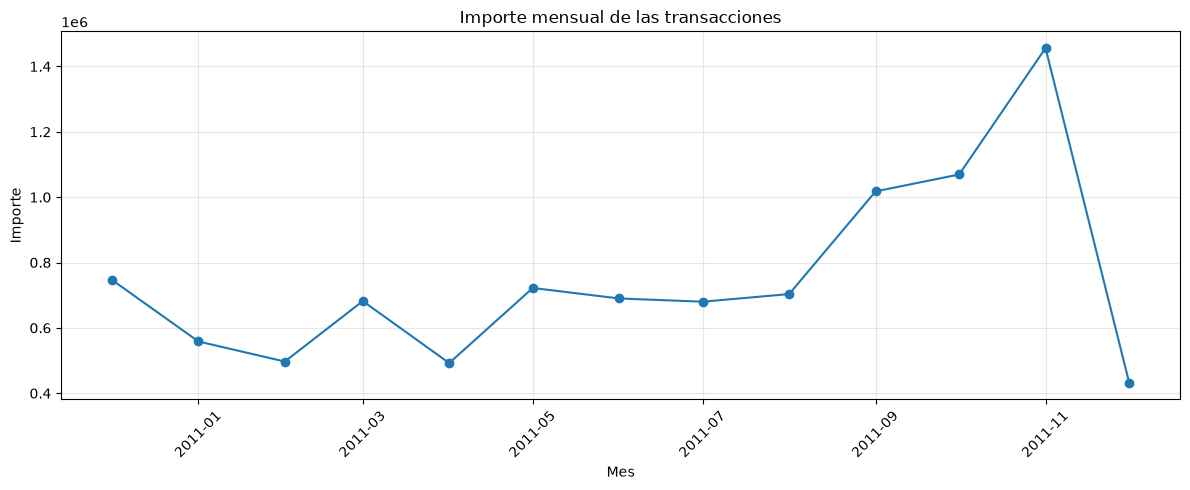

In [51]:
plt.figure(figsize=(12, 5))

plt.plot(
    ventas_mensuales['mes'],
    ventas_mensuales['ventas_netas'],
    marker='o'
)

plt.title('Importe mensual de las transacciones')
plt.xlabel('Mes')
plt.ylabel('Importe')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Identificar los productos con mayor importe

In [52]:
productos_top = (
    df_analisis_ventas
    .groupby('descripcion')['importe']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

display(productos_top)

,descripcion,importe
0,DOTCOM POSTAGE,206245.48
1,REGENCY CAKESTAND 3 TIER,164459.49
2,WHITE HANGING HEART T-LIGHT HOLDER,99612.42
3,PARTY BUNTING,98243.88
4,JUMBO BAG RED RETROSPOT,92175.79
5,RABBIT NIGHT LIGHT,66661.63
6,POSTAGE,66230.64
7,PAPER CHAIN KIT 50'S CHRISTMAS,63715.24
8,ASSORTED COLOUR BIRD ORNAMENT,58792.42
9,CHILLI LIGHTS,53746.66


In [53]:
productos_top = (
    df_analisis_ventas[
        ~df_analisis_ventas['descripcion'].isin(
            ['DOTCOM POSTAGE', 'POSTAGE']
        )
    ]
    .dropna(subset=['descripcion'])
    .groupby('descripcion')['importe']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

display(productos_top)

,descripcion,importe
0,REGENCY CAKESTAND 3 TIER,164459.49
1,WHITE HANGING HEART T-LIGHT HOLDER,99612.42
2,PARTY BUNTING,98243.88
3,JUMBO BAG RED RETROSPOT,92175.79
4,RABBIT NIGHT LIGHT,66661.63
5,PAPER CHAIN KIT 50'S CHRISTMAS,63715.24
6,ASSORTED COLOUR BIRD ORNAMENT,58792.42
7,CHILLI LIGHTS,53746.66
8,SPOTTY BUNTING,42030.67
9,JUMBO BAG PINK POLKADOT,41584.43


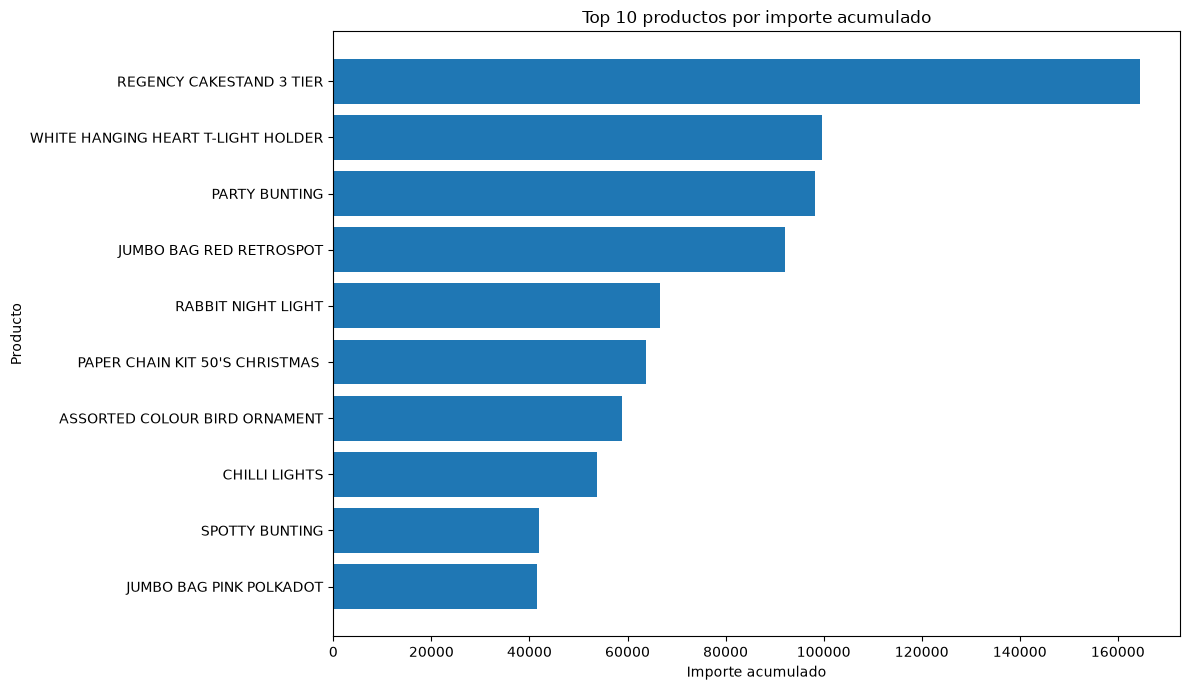

In [54]:
productos_grafica = productos_top.sort_values(
    'importe', ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    productos_grafica['descripcion'],
    productos_grafica['importe']
)

plt.title('Top 10 productos por importe acumulado')
plt.xlabel('Importe acumulado')
plt.ylabel('Producto')

plt.tight_layout()
plt.show()

* ¿Por qué elegimos barras horizontales?

* Permiten leer los nombres completos de los productos.

* Facilitan comparar los importes entre productos.

* Hacen más evidente cuáles tienen mayor valor acumulado.

* El importe acumulado no equivale necesariamente a la ganancia del negocio.<br>
  Además, el cálculo puede incluir devoluciones y cancelaciones; por ahora debemos describirlo<br>
  como importe de las transacciones.

#### ¿Qué países concentran el mayor importe de las transacciones?

In [55]:
#1. Calcular el importe por país
ventas_por_pais = (
    df_analisis_ventas
    .groupby('pais')['importe']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

display(ventas_por_pais)

,pais,importe
0,United Kingdom,8189252.304
1,Netherlands,284661.540
2,EIRE,262993.380
3,Germany,221509.470
4,France,197317.110
5,Australia,137009.770
6,Switzerland,56363.050
7,Spain,54756.030
8,Belgium,40910.960
9,Sweden,36585.410


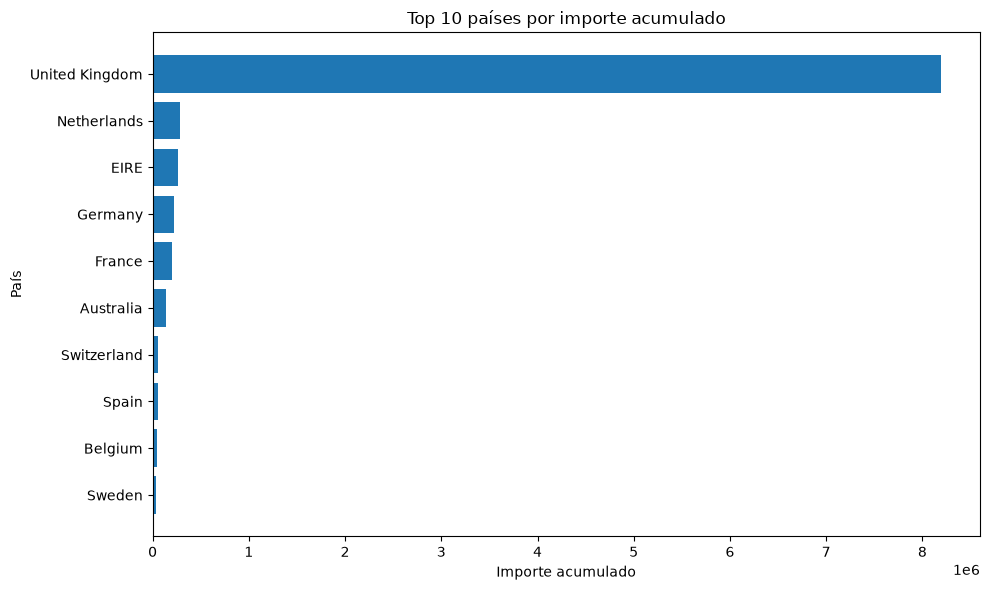

In [56]:
paises_grafica = ventas_por_pais.sort_values(
    'importe', ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    paises_grafica['pais'],
    paises_grafica['importe']
)

plt.title('Top 10 países por importe acumulado')
plt.xlabel('Importe acumulado')
plt.ylabel('País')

plt.tight_layout()
plt.show()

* País con mayor importe United Kingdom  ------>8,189,252.30

* Segundo lugar  Netherlands   -------------->284,661.54

* El Reino Unido destaca ampliamente: su importe acumulado es aproximadamente 29 veces el de los Países Bajos.

* También aparecen Irlanda (EIRE), Alemania y Francia entre los países con mayor importe acumulado después de los dos primeros.

* Insight preliminar

* El importe de las transacciones está fuertemente concentrado en el Reino Unido.<br> Esto sugiere que es el principal mercado de la empresa<br> dentro de los datos analizados.

* Todavía estamos sumando importes que pueden incluir devoluciones y cancelaciones.